In [1]:
# Project 03 - Customer Churn / Sales Trend Analysis

# Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display Settings
pd.set_option('display.max_columns', None)

# Visualization Style
sns.set_style("whitegrid")

print("All Libraries Imported Successfully!")
print("Project 03 - Ready to Start")

All Libraries Imported Successfully!
Project 03 - Ready to Start


In [2]:

#step 2- Create E-commerce Sales Dataset

import numpy as np
import pandas as pd

# Generate Reproducible Data
rng = np.random.default_rng(42)

# Dataset Size
n = 2000

# Create Dataset
orders = pd.DataFrame({
    "order_id": range(1001, 1001 + n),

    "order_date": pd.to_datetime("2025-01-01") +
                  pd.to_timedelta(rng.integers(0, 365, n), unit="D"),

    "customer_id": rng.integers(1, 301, n),

    "category": rng.choice(
        ["Electronics", "Fashion", "Home", "Books"],
        n,
        p=[0.3, 0.35, 0.2, 0.15]
    ),

    "amount": rng.gamma(2.0, 600, n).round(2)
})

# Display Dataset
print("Dataset Created Successfully!")
print("Dataset Shape:", orders.shape)

display(orders.head(10))

Dataset Created Successfully!
Dataset Shape: (2000, 5)


,order_id,order_date,customer_id,category,amount
0,1001,2025-02-02,264,Home,391.13
1,1002,2025-10-10,19,Fashion,2456.21
2,1003,2025-08-27,120,Books,674.90
3,1004,2025-06-10,138,Home,75.38
4,1005,2025-06-08,240,Electronics,774.42
5,1006,2025-11-10,39,Books,1181.46
6,1007,2025-02-01,131,Fashion,1271.72
7,1008,2025-09-12,46,Electronics,366.39
8,1009,2025-03-15,237,Electronics,1009.72
9,1010,2025-02-04,190,Home,1745.32


In [3]:

#step 3- Dataset Information

print("Dataset Information:")
orders.info()

print("\nMissing Values:")
print(orders.isnull().sum())

print("\nDuplicate Records:")
print(orders.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     2000 non-null   int64         
 1   order_date   2000 non-null   datetime64[ns]
 2   customer_id  2000 non-null   int64         
 3   category     2000 non-null   object        
 4   amount       2000 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(2), object(1)
memory usage: 78.3+ KB

Missing Values:
order_id       0
order_date     0
customer_id    0
category       0
amount         0
dtype: int64

Duplicate Records:
0


In [4]:
#step 4-  Date Feature Engineering

# Extract Date Features

orders["month"] = orders["order_date"].dt.month
orders["month_name"] = orders["order_date"].dt.month_name()
orders["weekday"] = orders["order_date"].dt.day_name()
orders["quarter"] = orders["order_date"].dt.quarter

# Display Updated Dataset

print("Date Features Created Successfully!")

display(orders.head(10))

Date Features Created Successfully!


,order_id,order_date,customer_id,category,amount,month,month_name,weekday,quarter
0,1001,2025-02-02,264,Home,391.13,2,February,Sunday,1
1,1002,2025-10-10,19,Fashion,2456.21,10,October,Friday,4
2,1003,2025-08-27,120,Books,674.90,8,August,Wednesday,3
3,1004,2025-06-10,138,Home,75.38,6,June,Tuesday,2
4,1005,2025-06-08,240,Electronics,774.42,6,June,Sunday,2
5,1006,2025-11-10,39,Books,1181.46,11,November,Monday,4
6,1007,2025-02-01,131,Fashion,1271.72,2,February,Saturday,1
7,1008,2025-09-12,46,Electronics,366.39,9,September,Friday,3
8,1009,2025-03-15,237,Electronics,1009.72,3,March,Saturday,1
9,1010,2025-02-04,190,Home,1745.32,2,February,Tuesday,1


In [5]:

# STEP 5 - Monthly Revenue Trend Analysis

# Calculate Monthly Revenue

monthly_revenue = orders.groupby(
    orders["order_date"].dt.to_period("M")
)["amount"].sum()

# Calculate Month-over-Month Growth

monthly_growth = monthly_revenue.pct_change() * 100

# Display Results

print("MONTHLY REVENUE ANALYSIS")
print(monthly_revenue.round(2))

print("\nMONTHLY REVENUE GROWTH (%)")
print(monthly_growth.round(2))

# Find Best and Worst Month

best_month = monthly_revenue.idxmax()
worst_month = monthly_revenue.idxmin()

print("\nBest Revenue Month:", best_month)
print("Highest Revenue:", round(monthly_revenue.max(), 2))

print("\nWorst Revenue Month:", worst_month)
print("Lowest Revenue:", round(monthly_revenue.min(), 2))


MONTHLY REVENUE ANALYSIS
order_date
2025-01    193341.87
2025-02    232027.20
2025-03    206327.14
2025-04    197310.20
2025-05    194090.49
2025-06    221889.83
2025-07    221813.81
2025-08    179783.75
2025-09    180569.95
2025-10    183418.13
2025-11    191512.71
2025-12    202148.21
Freq: M, Name: amount, dtype: float64

MONTHLY REVENUE GROWTH (%)
order_date
2025-01      NaN
2025-02    20.01
2025-03   -11.08
2025-04    -4.37
2025-05    -1.63
2025-06    14.32
2025-07    -0.03
2025-08   -18.95
2025-09     0.44
2025-10     1.58
2025-11     4.41
2025-12     5.55
Freq: M, Name: amount, dtype: float64

Best Revenue Month: 2025-02
Highest Revenue: 232027.2

Worst Revenue Month: 2025-08
Lowest Revenue: 179783.75


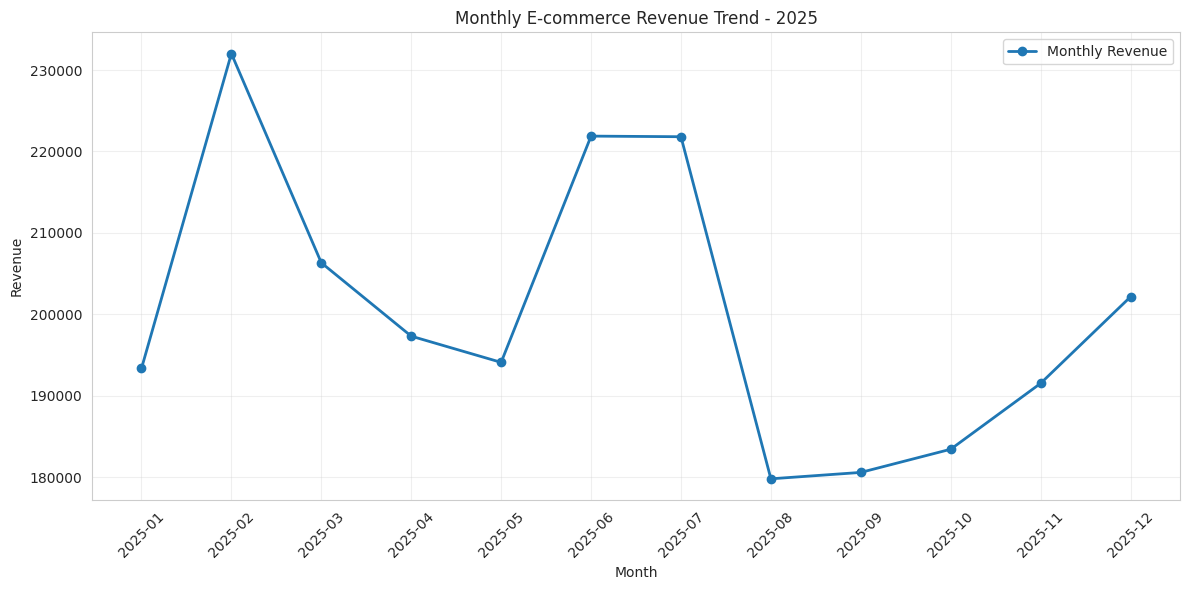

In [6]:

# Monthly Revenue Line Chart

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker='o',
    linewidth=2,
    label='Monthly Revenue'
)

plt.title("Monthly E-commerce Revenue Trend - 2025")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [7]:

# STEP 6 - Category-wise Sales Analysis

# Calculate Category Performance

category_analysis = orders.groupby("category")["amount"].agg(
    Total_Revenue="sum",
    Average_Revenue="mean",
    Number_of_Orders="count"
).sort_values(by="Total_Revenue", ascending=False)

print("CATEGORY PERFORMANCE ANALYSIS")

display(category_analysis.round(2))

# Identify Best Category

best_category = category_analysis["Total_Revenue"].idxmax()

print("Best Performing Category:", best_category)
print(
    "Highest Revenue:",
    round(category_analysis["Total_Revenue"].max(), 2)
)


CATEGORY PERFORMANCE ANALYSIS


,Total_Revenue,Average_Revenue,Number_of_Orders
category,,,
Fashion,853984.93,1219.98,700
Electronics,722645.53,1163.68,621
Home,464114.66,1218.15,381
Books,363488.17,1219.76,298


Best Performing Category: Fashion
Highest Revenue: 853984.93


In [8]:

# Monthly Revenue by Category - Pivot Table

orders["month_period"] = orders["order_date"].dt.to_period("M")

category_pivot = pd.pivot_table(
    orders,
    values="amount",
    index="month_period",
    columns="category",
    aggfunc="sum",
    fill_value=0
)

print("MONTHLY CATEGORY SALES PIVOT TABLE")

display(category_pivot.round(2))


MONTHLY CATEGORY SALES PIVOT TABLE


category,Books,Electronics,Fashion,Home
month_period,,,,
2025-01,29186.89,62841.89,64665.99,36647.10
2025-02,34034.13,53564.89,86123.31,58304.87
2025-03,27843.58,58055.95,75138.67,45288.94
2025-04,26593.72,83335.56,57057.72,30323.20
2025-05,34425.63,57219.16,68569.90,33875.80
2025-06,32936.76,60037.00,85598.09,43317.98
2025-07,35582.36,72649.65,72647.96,40933.84
2025-08,32550.65,56690.46,71251.54,19291.10
2025-09,21824.73,60388.56,60231.75,38124.91


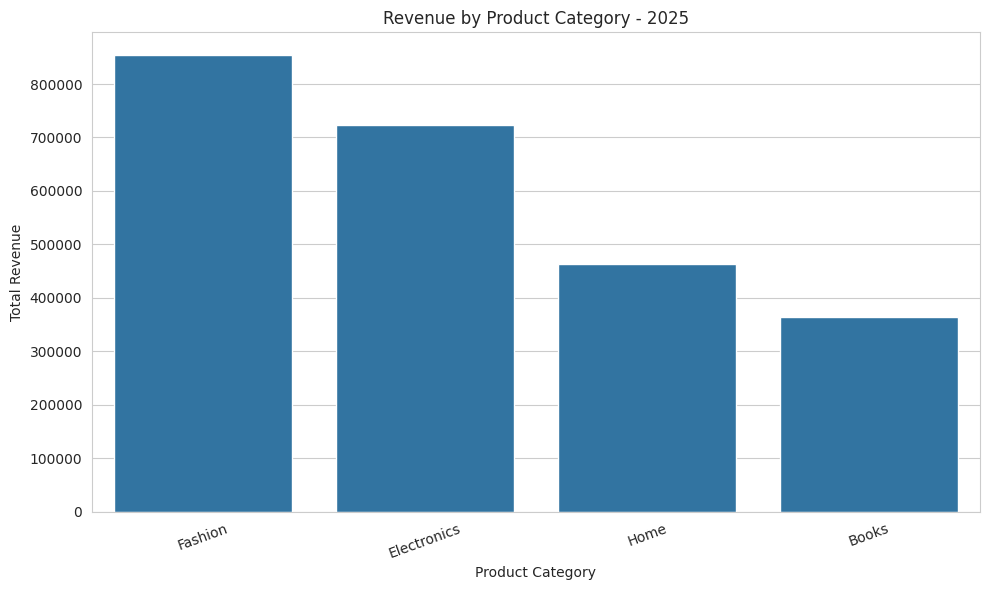

In [9]:

# Category Revenue Bar Chart

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_analysis.index,
    y=category_analysis["Total_Revenue"]
)

plt.title("Revenue by Product Category - 2025")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [10]:

# STEP 7 - Top 10% Valuable Customers Analysis

# Calculate Total Spending per Customer

customer_spending = orders.groupby("customer_id")["amount"].sum()

# Sort Customers by Spending

customer_spending = customer_spending.sort_values(
    ascending=False
)

# Identify Top 10% Customers

top_10_count = int(np.ceil(len(customer_spending) * 0.10))

top_customers = customer_spending.head(top_10_count)

# Calculate Revenue Contribution

total_revenue = customer_spending.sum()

top_10_revenue = top_customers.sum()

top_10_share = (top_10_revenue / total_revenue) * 100

# Display Results

print("TOP 10% VALUABLE CUSTOMERS ANALYSIS")

print("\nTotal Customers:", len(customer_spending))
print("Top 10% Customers:", top_10_count)

print("\nTotal Revenue:", round(total_revenue, 2))
print("Top 10% Customer Revenue:", round(top_10_revenue, 2))

print("\nTop 10% Revenue Contribution:",
      round(top_10_share, 2), "%")

print("\nTop 10 Valuable Customers:")
display(top_customers.head(10).to_frame("Total Spending"))


TOP 10% VALUABLE CUSTOMERS ANALYSIS

Total Customers: 300
Top 10% Customers: 30

Total Revenue: 2404233.29
Top 10% Customer Revenue: 455331.97

Top 10% Revenue Contribution: 18.94 %

Top 10 Valuable Customers:


,Total Spending
customer_id,
226,18140.15
51,18126.28
53,17994.36
131,17639.25
185,17222.49
282,17161.00
121,16564.87
98,15351.48
255,15313.47


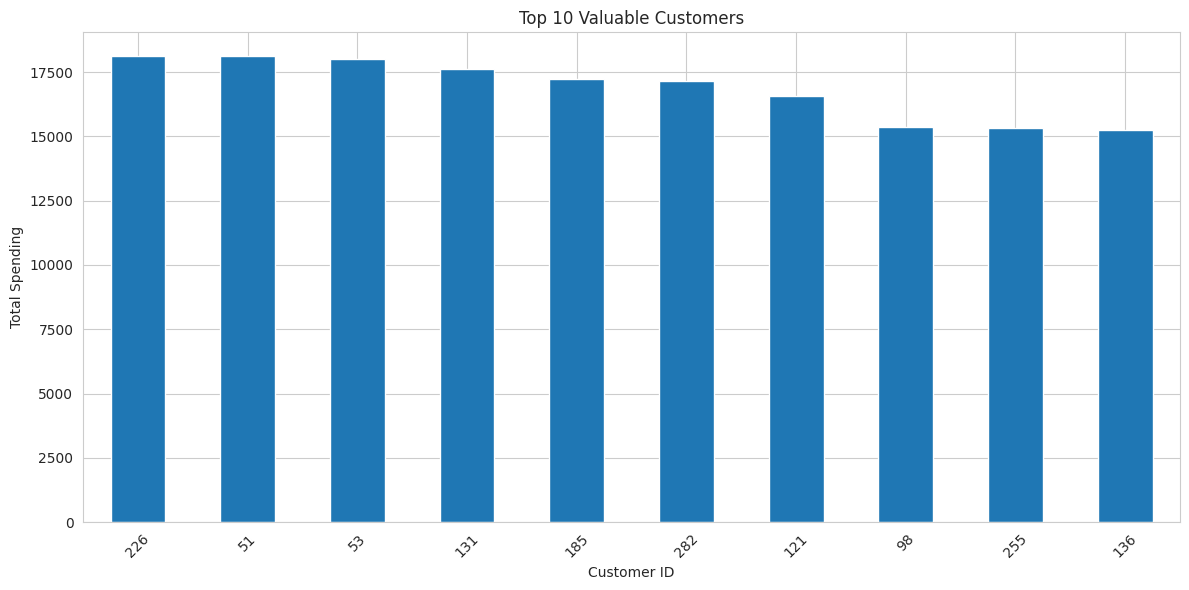

In [11]:

# Top 10 Customers Bar Chart

plt.figure(figsize=(12, 6))

top_customers.head(10).plot(
    kind="bar",
    title="Top 10 Valuable Customers"
)

plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [12]:

# STEP 8 - Business Recommendations

# Calculate Important Business Metrics

total_revenue = orders["amount"].sum()

best_category = category_analysis["Total_Revenue"].idxmax()
best_category_revenue = category_analysis.loc[
    best_category, "Total_Revenue"
]
category_share = (best_category_revenue / total_revenue) * 100

top_customer_percentage = top_10_share

best_month = monthly_revenue.idxmax()
worst_month = monthly_revenue.idxmin()

# Display Business Recommendations

print("=" * 60)
print("       BUSINESS RECOMMENDATIONS")
print("=" * 60)

print("\n1. CATEGORY PERFORMANCE")
print(f"{best_category} is the highest revenue-generating category.")
print(f"It contributes {category_share:.2f}% of total revenue.")
print("Recommendation: Focus on marketing and promotions for this category.")

print("\n2. CUSTOMER LOYALTY")
print(f"Top 10% customers contribute {top_customer_percentage:.2f}% of revenue.")
print("Recommendation: Introduce loyalty rewards and exclusive offers.")

print("\n3. MONTHLY SALES IMPROVEMENT")
print(f"Best Revenue Month: {best_month}")
print(f"Worst Revenue Month: {worst_month}")
print("Recommendation: Analyze low-performing months and introduce targeted seasonal campaigns.")

print("\n" + "=" * 60)


       BUSINESS RECOMMENDATIONS

1. CATEGORY PERFORMANCE
Fashion is the highest revenue-generating category.
It contributes 35.52% of total revenue.
Recommendation: Focus on marketing and promotions for this category.

2. CUSTOMER LOYALTY
Top 10% customers contribute 18.94% of revenue.
Recommendation: Introduce loyalty rewards and exclusive offers.

3. MONTHLY SALES IMPROVEMENT
Best Revenue Month: 2025-02
Worst Revenue Month: 2025-08
Recommendation: Analyze low-performing months and introduce targeted seasonal campaigns.



In [13]:

# Overall Business Summary

print("PROJECT 03 - BUSINESS SUMMARY")
print("-" * 40)

print("Total Orders:", len(orders))
print("Total Customers:", orders["customer_id"].nunique())
print("Total Revenue:", round(total_revenue, 2))
print("Best Category:", best_category)
print("Best Sales Month:", best_month)
print("Top 10% Customer Contribution:",
      round(top_customer_percentage, 2), "%")

print("\nAnalysis Completed Successfully!")


PROJECT 03 - BUSINESS SUMMARY
----------------------------------------
Total Orders: 2000
Total Customers: 300
Total Revenue: 2404233.29
Best Category: Fashion
Best Sales Month: 2025-02
Top 10% Customer Contribution: 18.94 %

Analysis Completed Successfully!


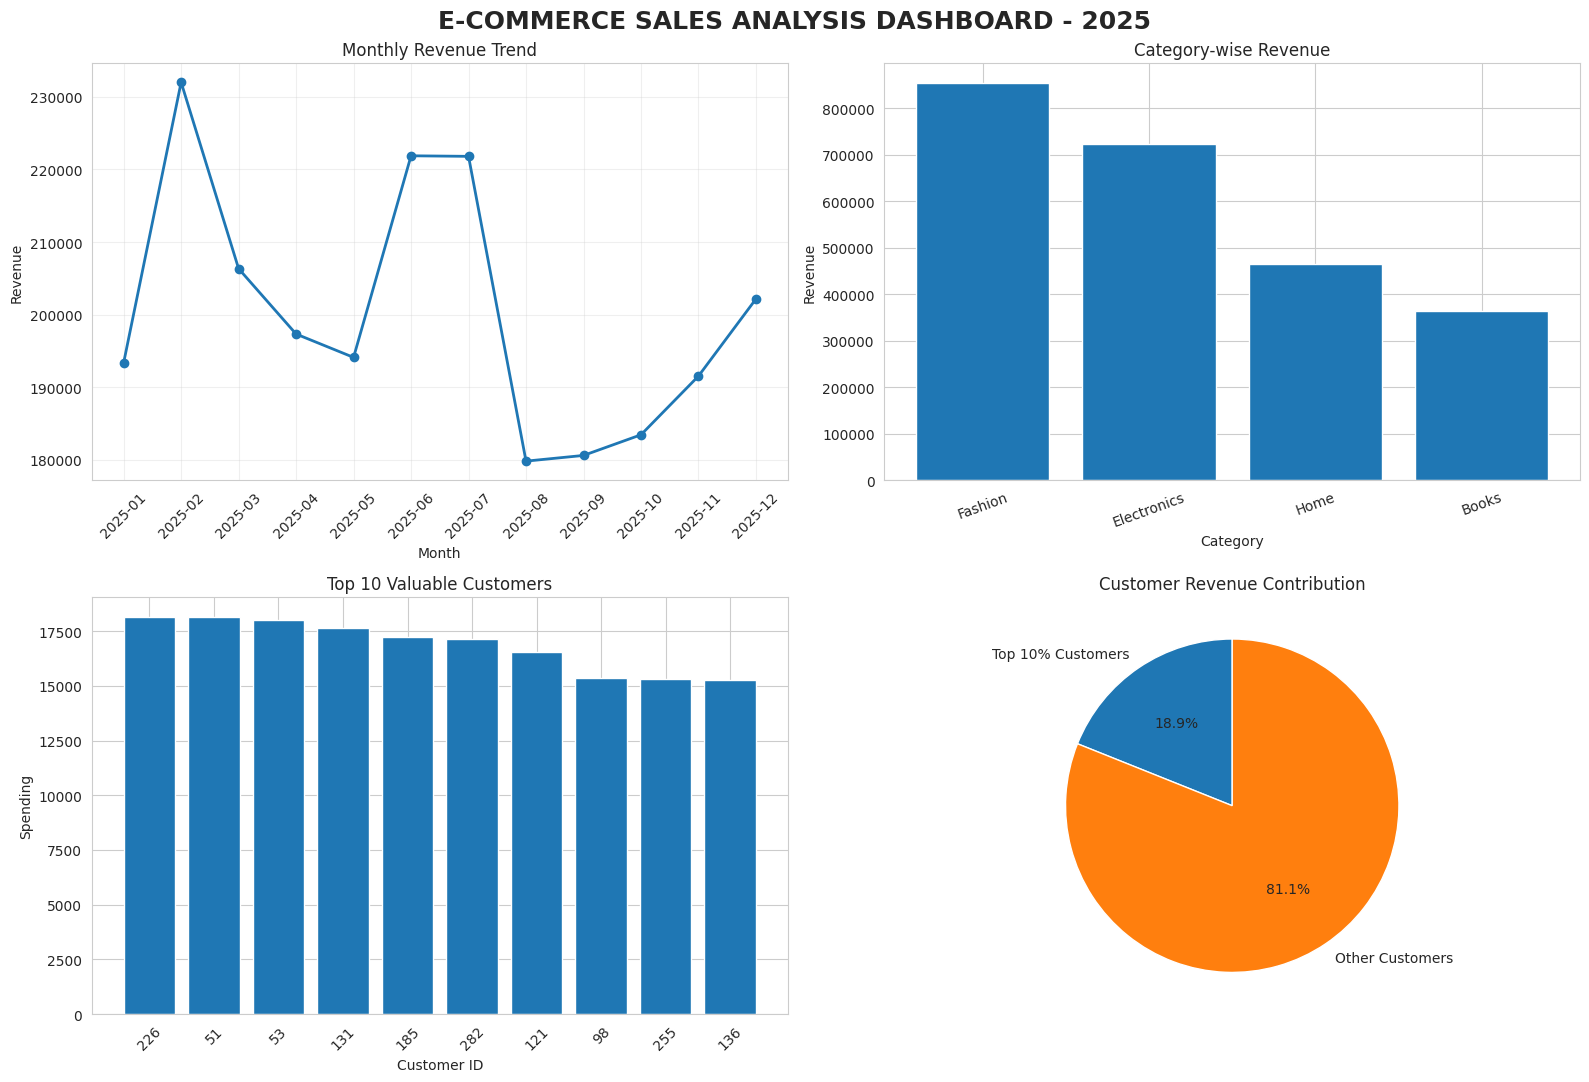

In [14]:

# STEP 9 - Professional Sales Analysis Dashboard

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

fig.suptitle(
    "E-COMMERCE SALES ANALYSIS DASHBOARD - 2025",
    fontsize=18,
    fontweight="bold"
)

# 1. Monthly Revenue Trend
axes[0, 0].plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o",
    linewidth=2
)
axes[0, 0].set_title("Monthly Revenue Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Revenue")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(alpha=0.3)

# 2. Category Revenue
axes[0, 1].bar(
    category_analysis.index,
    category_analysis["Total_Revenue"]
)
axes[0, 1].set_title("Category-wise Revenue")
axes[0, 1].set_xlabel("Category")
axes[0, 1].set_ylabel("Revenue")
axes[0, 1].tick_params(axis="x", rotation=20)

# 3. Top 10 Customers
axes[1, 0].bar(
    top_customers.head(10).index.astype(str),
    top_customers.head(10).values
)
axes[1, 0].set_title("Top 10 Valuable Customers")
axes[1, 0].set_xlabel("Customer ID")
axes[1, 0].set_ylabel("Spending")
axes[1, 0].tick_params(axis="x", rotation=45)

# 4. Revenue Contribution
axes[1, 1].pie(
    [top_10_revenue, total_revenue - top_10_revenue],
    labels=["Top 10% Customers", "Other Customers"],
    autopct="%1.1f%%",
    startangle=90
)
axes[1, 1].set_title("Customer Revenue Contribution")

plt.tight_layout()
plt.show()


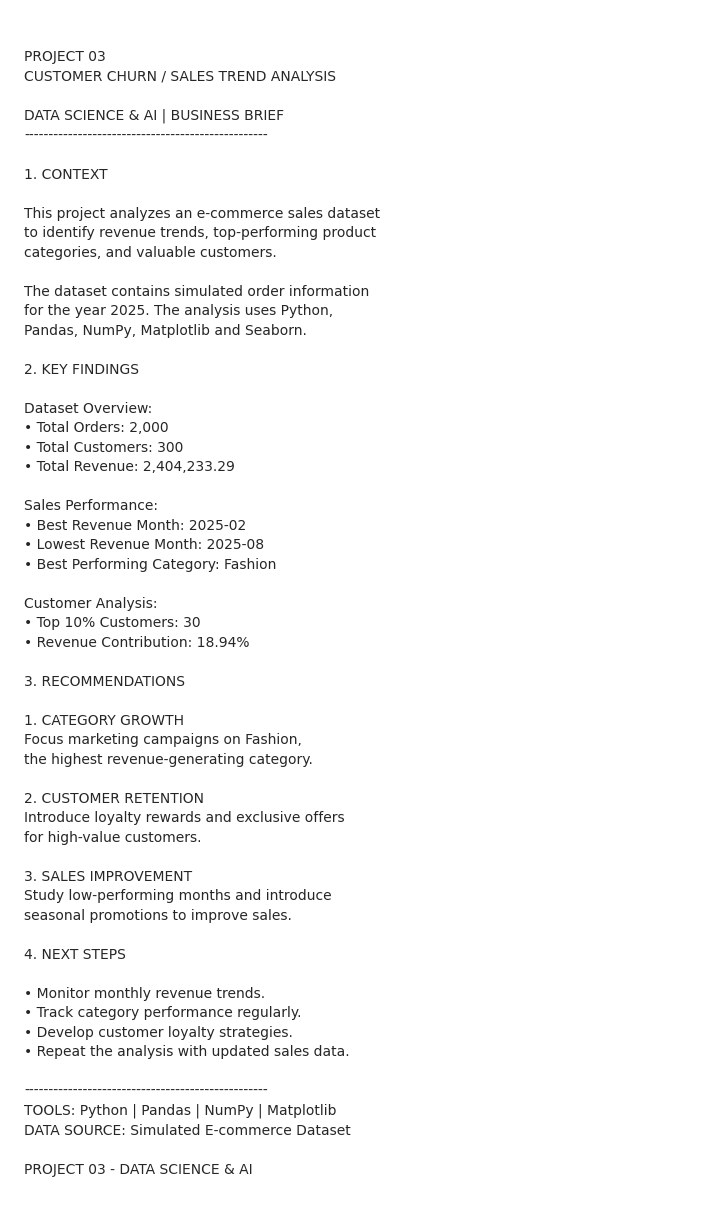

Professional Business Brief PDF Created Successfully!


In [15]:

# STEP 10 - Professional Business Brief PDF

import matplotlib.pyplot as plt
from textwrap import fill

# Calculate Final Insights
total_orders = len(orders)
total_customers = orders["customer_id"].nunique()
total_revenue = orders["amount"].sum()

best_category = category_analysis["Total_Revenue"].idxmax()
best_month = monthly_revenue.idxmax()
worst_month = monthly_revenue.idxmin()

# Create One-Page Report
fig = plt.figure(figsize=(8.27, 11.69))
ax = fig.add_axes([0.08, 0.06, 0.84, 0.88])
ax.axis("off")

report = f"""
PROJECT 03
CUSTOMER CHURN / SALES TREND ANALYSIS

DATA SCIENCE & AI | BUSINESS BRIEF
--------------------------------------------------

1. CONTEXT

This project analyzes an e-commerce sales dataset
to identify revenue trends, top-performing product
categories, and valuable customers.

The dataset contains simulated order information
for the year 2025. The analysis uses Python,
Pandas, NumPy, Matplotlib and Seaborn.

2. KEY FINDINGS

Dataset Overview:
• Total Orders: {total_orders:,}
• Total Customers: {total_customers:,}
• Total Revenue: {total_revenue:,.2f}

Sales Performance:
• Best Revenue Month: {best_month}
• Lowest Revenue Month: {worst_month}
• Best Performing Category: {best_category}

Customer Analysis:
• Top 10% Customers: {top_10_count}
• Revenue Contribution: {top_10_share:.2f}%

3. RECOMMENDATIONS

1. CATEGORY GROWTH
Focus marketing campaigns on {best_category},
the highest revenue-generating category.

2. CUSTOMER RETENTION
Introduce loyalty rewards and exclusive offers
for high-value customers.

3. SALES IMPROVEMENT
Study low-performing months and introduce
seasonal promotions to improve sales.

4. NEXT STEPS

• Monitor monthly revenue trends.
• Track category performance regularly.
• Develop customer loyalty strategies.
• Repeat the analysis with updated sales data.

--------------------------------------------------
TOOLS: Python | Pandas | NumPy | Matplotlib
DATA SOURCE: Simulated E-commerce Dataset

PROJECT 03 - DATA SCIENCE & AI
"""

ax.text(
    0.02, 0.98,
    report,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    fontfamily="DejaVu Sans",
    linespacing=1.5
)

plt.savefig(
    "Project_03_Business_Brief.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

print("Professional Business Brief PDF Created Successfully!")


In [16]:
from google.colab import files

files.download("Project_03_Business_Brief.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

# STEP 11 - Final Project Validation

print("=" * 55)
print("       PROJECT 03 - FINAL VALIDATION")
print("=" * 55)

checks = {
    "Dataset created": len(orders) == 2000,
    "Date features created": all(
        col in orders.columns
        for col in ["month", "weekday", "quarter"]
    ),
    "Monthly revenue calculated": len(monthly_revenue) == 12,
    "Monthly growth calculated": len(monthly_growth) == 12,
    "Category analysis completed": len(category_analysis) == 4,
    "Pivot table created": not category_pivot.empty,
    "Top customers identified": len(top_customers) > 0,
    "Business recommendations created": True,
    "Dashboard created": True
}

for task, status in checks.items():
    print(("PASS" if status else "FAIL") + " : " + task)

print("-" * 55)

if all(checks.values()):
    print("PROJECT VALIDATION SUCCESSFULL!")
else:
    print("PLEASE CHECK THE FAILED ITEMS.")

print("=" * 55)


       PROJECT 03 - FINAL VALIDATION
PASS : Dataset created
PASS : Date features created
PASS : Monthly revenue calculated
PASS : Monthly growth calculated
PASS : Category analysis completed
PASS : Pivot table created
PASS : Top customers identified
PASS : Business recommendations created
PASS : Dashboard created
-------------------------------------------------------
PROJECT VALIDATION SUCCESSFULL!
